# Agente inversor: métricas

1. **Definición** de cada métrica y por qué se reporta
2. **Verificación** con los ejemplos de la actividad
3. **Formato del reporte final**, ensayado sobre validación

El reporte de test se generará después con exactamente las mismas funciones
(`evaluation.compare`, `evaluation.summary`, `evaluation.plot_equity`). Este
notebook las ejecuta sobre validación, que ya se usó para decidir, para dejar
fijado de antemano qué se va a reportar y cómo.

In [1]:
import os
from pathlib import Path

# Ejecutar desde la raíz del repositorio, como la CLI.
if Path.cwd().name == "notebooks":
    os.chdir("..")

import numpy as np
import pandas as pd

from rl_games_sb import backtest, evaluation, investor

## 1. Definiciones

Sea $V_t$ el valor del portafolio al cierre del día $t$ ($t = 0, \dots, T$),
con $V_0$ = $100.000, $w_t$ la posición elegida al cierre de $t$ y
$w'_{t-1}$ la posición que se traía (después de su deriva por el precio).

**Mínimo pedido por la actividad:**

| Métrica | Fórmula | Qué responde |
|---|---|---|
| **Retorno acumulado** | $\dfrac{V_T}{V_0} - 1$ | ¿Cuánto creció o se redujo el capital en todo el período? |
| **Máximo drawdown** | $\min_t \left( \dfrac{V_t}{\max_{s \le t} V_s} - 1 \right)$ | ¿Cuál fue la peor caída desde un máximo anterior? Es lo que habría tenido que aguantar un inversionista en el peor momento. |
| **Costos de transacción** | $\sum_t c\,\lvert w_t - w'_{t-1}\rvert\,V_t$, con $c$ = 10 bps | ¿Cuántos dólares se pagaron por operar? |

**Adicionales**, porque la actividad pide considerar rendimiento, riesgo y
costos, y el retorno acumulado no distingue un período de 1 año de uno de 3:

| Métrica | Fórmula | Qué responde |
|---|---|---|
| Retorno anualizado | $(V_T / V_0)^{252/T} - 1$ | El retorno acumulado llevado a un año, para comparar períodos de distinta duración |
| Volatilidad anualizada | $\sigma(r_t)\,\sqrt{252}$, con $r_t = V_t/V_{t-1} - 1$ | Cuánto oscila el valor día a día |
| Sharpe | $\dfrac{\bar r_t}{\sigma(r_t)}\sqrt{252}$ | Retorno por unidad de riesgo (tasa libre de riesgo = 0) |
| Operaciones | número de días en que cambia la posición objetivo | Cuánto opera la estrategia |
| Exposición media | promedio de $w_t$ | Qué fracción del tiempo y del capital estuvo invertida |

**Detalles que importan:**

- El drawdown se mide sobre los cierres diarios: una caída dentro del día que
  se recupera al cierre no cuenta.
- Los costos son solo el costo real de 10 bps. La penalización de la
  recompensa v1 (400 bps) existe solo durante el aprendizaje y no se cobra al
  portafolio.
- Mantener 50 % obliga a reequilibrar un poco cada día, y ese costo sí entra
  en "costos". Pero un reequilibrio no cuenta como operación: solo cuenta un
  cambio de posición objetivo.

## 2. Verificación con los ejemplos de la actividad

La actividad da dos ejemplos: un activo que pasa de $100 a $105 rinde 5 %, y
un portafolio que sube de $100.000 a $150.000 y cae a $120.000 tiene un
drawdown de −20 %. `backtest.metrics` debe dar exactamente eso (también lo
verifican las pruebas automáticas).

In [2]:
def example(values):
    n = len(values)
    return backtest.metrics(pd.DataFrame({
        "value": values,
        "position": [1.0] * (n - 1) + [np.nan],
        "cost": [0.0] * (n - 1) + [np.nan],
    }))


ret = example([100.0, 105.0])
dd = example([100_000.0, 150_000.0, 120_000.0])
print(f"$100 → $105:                retorno acumulado {ret['total_return']:+.1%}")
print(f"$100.000 → $150.000 → $120.000: retorno acumulado {dd['total_return']:+.1%}, "
      f"máximo drawdown {dd['max_drawdown']:+.1%}")

$100 → $105:                retorno acumulado +5.0%
$100.000 → $150.000 → $120.000: retorno acumulado +20.0%, máximo drawdown -20.0%


## 3. El reporte final, ensayado sobre validación (2015)

`evaluation.compare(period)` ejecuta, sobre un mismo período y con las mismas
condiciones:

- el **agente RL final**: las 3 semillas congeladas en la parte 12, después de
  verificar sus hashes;
- **comprar y mantener**;
- el **agente aleatorio**, con las semillas 0 a 199.

Cada estrategia se resume en una fila: el agente con la **media** de sus 3
semillas y el aleatorio con la **mediana** de sus 200 corridas. El detalle por
semilla va en una segunda tabla, para que no se pueda esconder una semilla
mala detrás del promedio.

In [3]:
PERIOD = "valid"  # el reporte final usará "test"

runs = evaluation.compare(PERIOD)
metrics = evaluation.per_run(runs)
table = evaluation.summary(metrics)

report = pd.DataFrame({
    "Retorno acumulado": table["total_return"],
    "Máximo drawdown": table["max_drawdown"],
    "Costos": table["costs"],
    "Costos (% del capital inicial)": table["costs"] / investor.INITIAL_CAPITAL,
}).rename_axis("Estrategia")
report.style.format({
    "Retorno acumulado": "{:+.1%}",
    "Máximo drawdown": "{:+.1%}",
    "Costos": "${:,.0f}",
    "Costos (% del capital inicial)": "{:.2%}",
})

,Retorno acumulado,Máximo drawdown,Costos,Costos (% del capital inicial)
Estrategia,,,,
Agente RL,+56.2%,-9.6%,$983,0.98%
Comprar y mantener,+46.8%,-12.5%,$100,0.10%
Aleatorio,+6.2%,-12.7%,"$11,317",11.32%


**Tabla detallada:** todas las métricas, cada semilla del agente y la
dispersión del aleatorio.

In [4]:
LABELS = {
    "total_return": "retorno acumulado", "annual_return": "retorno anual", "volatility": "volatilidad anual",
    "sharpe": "Sharpe", "max_drawdown": "máximo drawdown", "trades": "operaciones", "costs": "costos ($)",
    "exposure": "exposición media",
}
random_metrics = metrics.loc[evaluation.RANDOM]
detail = pd.concat([
    metrics.loc[evaluation.AGENT].rename(index=lambda i: f"{evaluation.AGENT}, semilla {i}"),
    table.loc[[evaluation.AGENT]].rename(index={evaluation.AGENT: f"{evaluation.AGENT}, media"}),
    metrics.loc[evaluation.BUY_AND_HOLD].rename(index=lambda i: evaluation.BUY_AND_HOLD),
    random_metrics.quantile([0.05, 0.5, 0.95]).rename(index=lambda q: f"{evaluation.RANDOM}, percentil {q:.0%}"),
]).drop(columns="final_value").rename(columns=LABELS)
detail.style.format({
    "retorno acumulado": "{:+.1%}", "retorno anual": "{:+.1%}", "volatilidad anual": "{:.1%}",
    "Sharpe": "{:.2f}", "máximo drawdown": "{:+.1%}", "operaciones": "{:.0f}", "costos ($)": "{:,.0f}",
    "exposición media": "{:.2f}",
})

,retorno acumulado,retorno anual,volatilidad anual,Sharpe,máximo drawdown,operaciones,costos ($),exposición media
"Agente RL, semilla 0",+57.7%,+58.0%,23.6%,2.05,-9.1%,13,"1,238",0.60
"Agente RL, semilla 1",+71.6%,+72.0%,25.1%,2.28,-8.4%,9,810,0.82
"Agente RL, semilla 2",+39.3%,+39.5%,26.3%,1.39,-11.5%,13,901,0.78
"Agente RL, media",+56.2%,+56.5%,25.0%,1.91,-9.6%,12,983,0.73
Comprar y mantener,+46.8%,+47.0%,28.9%,1.47,-12.5%,1,100,1.00
"Aleatorio, percentil 5%",-13.7%,-13.8%,13.8%,-0.94,-20.7%,157,"9,980",0.46
"Aleatorio, percentil 50%",+6.2%,+6.2%,17.4%,0.43,-12.7%,168,"11,317",0.50
"Aleatorio, percentil 95%",+36.7%,+36.8%,23.2%,1.52,-7.2%,180,"13,022",0.55


Los percentiles del aleatorio se calculan por separado para cada columna, así
que una fila de percentil no corresponde a una corrida concreta.

**Curva de capital y drawdown:**

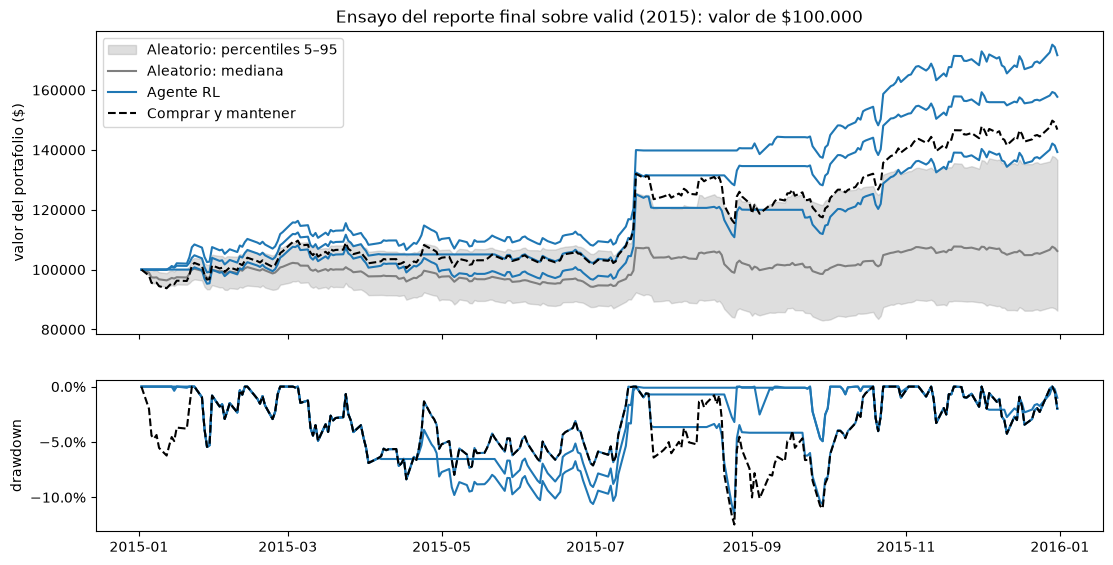

In [5]:
evaluation.plot_equity(runs, f"Ensayo del reporte final sobre {PERIOD} (2015): valor de $100.000")

**Cómo leer este ensayo:** los números son los de las partes 9 y 11 (el
agente final es DQN v1). Lo que fija este notebook es el formato: el reporte
de test tendrá exactamente estas dos tablas y esta figura, con
`PERIOD = "test"`, y se generará una sola vez.